# Tabular Q-learning and SARSA for Blackjack

Neste notebook, aplicamos os métodos tabulares **Q-learning** (off-policy) e **SARSA** (on-policy) para resolver o jogo **Blackjack** (Vinte-e-Um).

Ambiente: [Gymnasium Blackjack-v1](https://gymnasium.farama.org/environments/toy_text/blackjack/).

## Execução local
Requer Python 3.10+ e um kernel apontando para um ambiente virtual. Dependências na primeira célula de código.

In [1]:
# Instalação no kernel ativo (%pip, não !pip). Execute uma vez e reinicie o kernel se necessário.
# [toy-text] inclui o pygame, usado no render do Blackjack.
# imageio_ffmpeg empacota o binário do ffmpeg: não é preciso instalar ffmpeg no sistema.
%pip install -q "gymnasium[toy-text]>=1.0,<2.0" numpy matplotlib seaborn imageio imageio_ffmpeg tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
import sys

import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)               # legado
rng = np.random.default_rng(SEED)  # preferir este gerador nas próximas células

# Registro de versões
print(f"python {sys.version.split()[0]} | gymnasium {gym.__version__} | numpy {np.__version__}")

python 3.12.12 | gymnasium 1.4.0 | numpy 2.5.4


In [3]:
# Configuração do ambiente Blackjack-v1 (parametrizada para facilitar experimentos)
# SAB = True segue exatamente as regras do livro de Sutton & Barto (Example 5.1)
# NATURAL = True paga +1.5 para Blackjack natural (21 com 2 cartas), se SAB = False
SAB = True
NATURAL = False

env = gym.make(
    "Blackjack-v1",
    natural=NATURAL,
    sab=SAB,
    render_mode="rgb_array",
)
env.action_space.seed(SEED)

print("Espaço de observação:", env.observation_space)
print("Espaço de ações     :", env.action_space)
env.spec

Espaço de observação: Tuple(Discrete(32), Discrete(11), Discrete(2))
Espaço de ações     : Discrete(2)


EnvSpec(id='Blackjack-v1', entry_point='gymnasium.envs.toy_text.blackjack:BlackjackEnv', reward_threshold=None, nondeterministic=False, max_episode_steps=None, order_enforce=True, disable_env_checker=False, kwargs={'sab': True, 'natural': False, 'render_mode': 'rgb_array'}, namespace=None, name='Blackjack', version=1, additional_wrappers=(), vector_entry_point=None)

Shape do espaço de estados: (np.int64(32), np.int64(11), np.int64(2)) (total = 704 entradas na tabela)
Actions: {0: 'stick (parar)', 1: 'hit (pedir carta)'}
Estado inicial: (15, 2, 0) -> (soma_jogador=15, dealer=2, ás_usável=0)


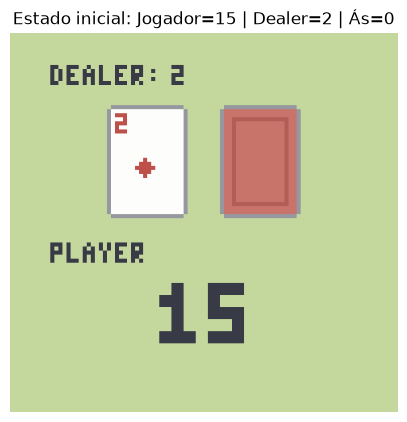

In [4]:
# Convenção de ações do Blackjack (Gymnasium)
STICK, HIT = 0, 1
ACTION_NAMES = ["stick (parar)", "hit (pedir carta)"]

# Dimensões derivadas do espaço de estados Tuple(Discrete(32), Discrete(11), Discrete(2))
# Estado = (soma_do_jogador, carta_visivel_dealer, as_usavel)
STATE_SHAPE = tuple(space.n for space in env.observation_space.spaces)
N_STATES = int(np.prod(STATE_SHAPE))
N_ACTIONS = env.action_space.n
assert len(ACTION_NAMES) == N_ACTIONS, "Lista de ações incompatível com o ambiente"
print("Shape do espaço de estados:", STATE_SHAPE, f"(total = {N_STATES} entradas na tabela)")
print("Actions:", dict(enumerate(ACTION_NAMES)))


def plot_image(img, title=None):
    """Exibe o frame renderizado do Blackjack."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(img)
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.show()


# Primeira chamada de reset: aplica a semente do ambiente
obs, info = env.reset(seed=SEED)
print(f"Estado inicial: {obs} -> (soma_jogador={obs[0]}, dealer={obs[1]}, ás_usável={obs[2]})")
plot_image(env.render(), f"Estado inicial: Jogador={obs[0]} | Dealer={obs[1]} | Ás={obs[2]}")

In [5]:
# step() devolve: (próximo estado, recompensa, terminated, truncated, info)
#   recompensa: +1.0 (vitória), 0.0 (empate), -1.0 (derrota) [ou +1.5 em natural quando natural=True, sab=False]
#   terminated: True quando o jogador para (stick) ou estoura (> 21)

print("mão | passo | ação               | estado (jog, deal, ás) | recompensa | terminated")
for hand in range(1, 6):
    state, _ = env.reset()
    step = 0
    while True:
        step += 1
        action = env.action_space.sample()
        next_state, reward, terminated, truncated, info = env.step(action)
        print(f"{hand:>3} | {step:>5} | {ACTION_NAMES[action]:<18} | {str(state):<22} -> {str(next_state):<14} | "
              f"{reward:>10.1f} | {terminated}")
        state = next_state
        if terminated or truncated:
            break

mão | passo | ação               | estado (jog, deal, ás) | recompensa | terminated
  1 |     1 | stick (parar)      | (13, 10, 0)            -> (13, 10, 0)    |        1.0 | True
  2 |     1 | hit (pedir carta)  | (20, 10, 0)            -> (30, 10, 0)    |       -1.0 | True
  3 |     1 | hit (pedir carta)  | (8, 6, 0)              -> (18, 6, 0)     |        0.0 | False
  3 |     2 | stick (parar)      | (18, 6, 0)             -> (18, 6, 0)     |        1.0 | True
  4 |     1 | stick (parar)      | (14, 6, 0)             -> (14, 6, 0)     |       -1.0 | True
  5 |     1 | hit (pedir carta)  | (21, 2, 1)             -> (21, 2, 0)     |        0.0 | False
  5 |     2 | stick (parar)      | (21, 2, 0)             -> (21, 2, 0)     |        1.0 | True


In [6]:
def random_policy_baseline(env, n_episodes=2000):
    """Avalia uma política uniforme no Blackjack: retorno médio, taxas de vitória/empate/derrota e passos."""
    rewards, lengths = [], []
    for _ in range(n_episodes):
        env.reset()
        done, steps, ep_reward = False, 0, 0.0
        while not done:
            _, reward, terminated, truncated, _ = env.step(env.action_space.sample())
            done = terminated or truncated
            ep_reward = reward
            steps += 1
        rewards.append(ep_reward)
        lengths.append(steps)
    rewards = np.asarray(rewards)
    win_rate = float(np.mean(rewards > 0))
    draw_rate = float(np.mean(rewards == 0))
    loss_rate = float(np.mean(rewards < 0))
    return float(np.mean(rewards)), win_rate, draw_rate, loss_rate, float(np.mean(lengths))

mean_ret, win_r, draw_r, loss_r, mean_len = random_policy_baseline(env)
print(f"Baseline aleatória: retorno médio = {mean_ret:+.3f} | "
      f"vitórias = {win_r:.1%} | empates = {draw_r:.1%} | derrotas = {loss_r:.1%} | passos = {mean_len:.2f}")
env.reset();

Baseline aleatória: retorno médio = -0.419 | vitórias = 26.7% | empates = 4.8% | derrotas = 68.5% | passos = 1.38


In [7]:
from pathlib import Path
from IPython.display import Video, display

VIDEO_DIR = Path("videos")


def make_env():
    """Cria o ambiente Blackjack-v1 com a configuração atual de SAB e NATURAL."""
    e = gym.make("Blackjack-v1", natural=NATURAL, sab=SAB, render_mode="rgb_array")
    e.action_space.seed(SEED)
    return e


def record_episode(policy, prefix, n_hands=5, fps=1):
    """Grava `n_hands` mãos consecutivas em MP4 (Blackjack dura 1-3 passos por mão)."""
    rec_env = make_env()
    VIDEO_DIR.mkdir(exist_ok=True)
    path = VIDEO_DIR / f"{prefix}.mp4"

    frames, outcomes = [], []
    try:
        for h in range(n_hands):
            state, _ = rec_env.reset(seed=SEED + h)
            frames.append(rec_env.render())
            done = False
            while not done:
                action = policy(state)
                state, reward, terminated, truncated, _ = rec_env.step(action)
                frames.append(rec_env.render())
                done = terminated or truncated
            outcomes.append("vitória" if reward > 0 else ("empate" if reward == 0 else "derrota"))
    finally:
        rec_env.close()

    imageio.mimwrite(path, frames, fps=fps)
    print(f"{prefix}: {n_hands} mãos ({len(frames)} frames) | desfechos: {outcomes} | {path}")
    return path


_rng_rand = np.random.default_rng(SEED + 3)
def random_policy(state):
    return int(_rng_rand.integers(N_ACTIONS))


before_training = record_episode(random_policy, "blackjack_before_training")
display(Video(str(before_training), embed=True, width=400))

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (384, 376) to (384, 384) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


blackjack_before_training: 5 mãos (15 frames) | desfechos: ['derrota', 'derrota', 'derrota', 'derrota', 'derrota'] | videos/blackjack_before_training.mp4


In [8]:
from base64 import b64encode
from IPython.display import HTML


def render_mp4(video_path, width=400) -> HTML:
    """Embute um MP4 local no notebook via data URI (base64) e devolve o HTML pronto."""
    data = b64encode(Path(video_path).read_bytes()).decode("ascii")
    return HTML(
        f'<video width="{width}" controls>'
        f'<source src="data:video/mp4;base64,{data}" type="video/mp4">'
        f"</video>"
    )


display(render_mp4(before_training))

## Building a Q-learning agent (off-policy) or a SARSA agent (on-policy)

![QL](https://github.com/dudeperf3ct/RL_Notebooks/blob/master/TD/images/ql.png?raw=1)
![SARSA](https://github.com/dudeperf3ct/RL_Notebooks/blob/master/TD/images/sarsa.png?raw=1)

In [9]:
class BlackjackAgent:

    def __init__(
        self,
        alpha_learning_rate: float,
        initial_epsilon: float,
        epsilon_decay: float,
        final_epsilon: float,
        gamma_discount_factor: float,
        state_shape: tuple,
        action_size: int,
        is_using_Sarsa: bool,
        seed: int = 0,
        verbose: bool = True,
    ):
        """Agente tabular com política ε-greedy (Q-learning ou SARSA) para Blackjack.

        Args:
            alpha_learning_rate: taxa de aprendizado α, em (0, 1].
            initial_epsilon: ε inicial.
            epsilon_decay: decremento LINEAR de ε por chamada de decay_epsilon().
            final_epsilon: piso de ε.
            gamma_discount_factor: fator de desconto γ, em [0, 1].
            state_shape: tupla com dimensões do espaço de estados (32, 11, 2).
            action_size: número de ações discretas (2: stick=0, hit=1).
            is_using_Sarsa: True = SARSA (on-policy); False = Q-learning (off-policy).
            seed: semente do gerador do agente (única fonte de aleatoriedade).
            verbose: imprime o método selecionado.
        """
        assert 0.0 < alpha_learning_rate <= 1.0, "α deve estar em (0, 1]"
        assert 0.0 <= gamma_discount_factor <= 1.0, "γ deve estar em [0, 1]"
        assert 0.0 <= final_epsilon <= initial_epsilon <= 1.0, "ε inconsistente"

        self.alpha_learning_rate = alpha_learning_rate
        self.gamma_discount_factor = gamma_discount_factor
        self.epsilon = initial_epsilon
        self.epsilon_decay = epsilon_decay
        self.final_epsilon = final_epsilon
        self.state_shape = state_shape
        self.action_size = action_size
        self.is_using_Sarsa = is_using_Sarsa

        self.training_error = []  # δ (com sinal) por atualização
        self.q_table = np.zeros((*state_shape, action_size))
        self.rng = np.random.default_rng(seed)

        if verbose:
            print("Using Sarsa method" if is_using_Sarsa else "Using Q-learning method")

    def get_Q_Table(self):
        return self.q_table

    def eval_state(self, state):
        """Ação gulosa, com desempate aleatório entre ações de mesmo Q."""
        q = self.q_table[state]
        best = np.flatnonzero(q == q.max())
        return int(self.rng.choice(best))

    greedy_action = eval_state

    def choose_action(self, state):
        """ε-greedy: explora com prob. ε, senão age de forma gulosa."""
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.action_size))
        return self.eval_state(state)

    def update(self, state, action, reward, terminated, next_state, next_action=None):
        """Atualização TD. Passe `terminated`, NUNCA `terminated or truncated`.
        No SARSA, next_action deve ser a ação que será EXECUTADA em next_state."""
        if terminated:
            target = reward
        elif self.is_using_Sarsa:
            assert next_action is not None, "SARSA exige next_action"
            target = reward + self.gamma_discount_factor * self.q_table[next_state][next_action]
        else:
            target = reward + self.gamma_discount_factor * np.max(self.q_table[next_state])

        td_error = target - self.q_table[state][action]
        self.q_table[state][action] += self.alpha_learning_rate * td_error
        self.training_error.append(td_error)

    def decay_epsilon(self):
        self.epsilon = max(self.final_epsilon, self.epsilon - self.epsilon_decay)

## Hyperparameters

In [10]:
# Configuração do experimento
# No Blackjack, cada episódio é curto (1 a 3 decisões) e o baralho infinito gera alta variância,
# portanto usamos α menor (0.03), γ = 1.0 (sem desconto) e 50.000 episódios.
CONFIG = dict(
    alpha_learning_rate=0.03,
    nb_max_episodes=50_000,
    start_epsilon=1.0,
    final_epsilon=0.05,
    gamma_discount_factor=1.0,
    test_freq=2_500,
)

alpha_learning_rate   = CONFIG["alpha_learning_rate"]
nb_max_episodes       = CONFIG["nb_max_episodes"]
start_epsilon         = CONFIG["start_epsilon"]
final_epsilon         = CONFIG["final_epsilon"]
gamma_discount_factor = CONFIG["gamma_discount_factor"]
test_freq             = CONFIG["test_freq"]

# Decaimento LINEAR por EPISÓDIO
epsilon_decay = (start_epsilon - final_epsilon) / nb_max_episodes

is_using_Sarsa = False  # True = SARSA; False = Q-learning


def make_agent(use_sarsa: bool, seed: int = SEED, verbose: bool = True) -> "BlackjackAgent":
    return BlackjackAgent(
        alpha_learning_rate=alpha_learning_rate,
        initial_epsilon=start_epsilon,
        epsilon_decay=epsilon_decay,
        final_epsilon=final_epsilon,
        gamma_discount_factor=gamma_discount_factor,
        state_shape=STATE_SHAPE,
        action_size=N_ACTIONS,
        is_using_Sarsa=use_sarsa,
        seed=seed,
        verbose=verbose,
    )


agent = make_agent(is_using_Sarsa)

eps_mean = (start_epsilon + final_epsilon) / 2
print(f"ε: {start_epsilon} → {final_epsilon} | decay/episódio = {epsilon_decay:.2e} | ε médio ≈ {eps_mean:.3f}")

Using Q-learning method
ε: 1.0 → 0.05 | decay/episódio = 1.90e-05 | ε médio ≈ 0.525


### Avaliação da Política (Test Accuracy / Retorno Médio)

In [11]:
def evaluate_policy(agent, eval_env, n_episodes=2000, rng=None):
    """Avalia a política gulosa (ε = 0).
    Retorna dict com (mean_reward, win_rate, draw_rate, loss_rate, mean_len)."""
    rng = rng if rng is not None else np.random.default_rng(SEED + 1)
    rewards, lengths = [], []
    for _ in range(n_episodes):
        state, _ = eval_env.reset()
        steps = 0
        while True:
            steps += 1
            q = agent.q_table[state]
            action = int(rng.choice(np.flatnonzero(q == q.max())))
            state, reward, terminated, truncated, _ = eval_env.step(action)
            if terminated or truncated:
                rewards.append(reward)
                lengths.append(steps)
                break
    rewards = np.asarray(rewards, dtype=float)
    return dict(
        mean_reward=float(np.mean(rewards)),
        win_rate=float(np.mean(rewards > 0)),
        draw_rate=float(np.mean(rewards == 0)),
        loss_rate=float(np.mean(rewards < 0)),
        mean_len=float(np.mean(lengths)),
    )


eval_env = make_env()


def test_accurracy(num_episodes=2000):
    return evaluate_policy(agent, eval_env, num_episodes)["win_rate"]

## Playing and Training

In [12]:
from tqdm import tqdm


def train(use_sarsa, seed=SEED, n_episodes=None, eval_every=None, n_eval=2000, verbose=True):
    """Treina um agente do zero no Blackjack-v1. Retorna (agent, hist)."""
    n_episodes = n_episodes or nb_max_episodes
    eval_every = eval_every or test_freq

    train_env, eval_env = make_env(), make_env()
    agent = make_agent(use_sarsa, seed, verbose=verbose)
    eval_rng = np.random.default_rng(seed + 1)

    hist = dict(
        reward=[],
        steps=[],
        eval_episode=[],
        eval_return=[],
        eval_win=[],
        eval_draw=[],
        eval_loss=[],
        eval_len=[],
    )

    for ep in tqdm(range(n_episodes), disable=not verbose):
        state, _ = train_env.reset(seed=seed if ep == 0 else None)
        action = agent.choose_action(state) if use_sarsa else None
        ep_reward, ep_steps, done = 0.0, 0, False

        while not done:
            if not use_sarsa:
                action = agent.choose_action(state)
            next_state, reward, terminated, truncated, _ = train_env.step(action)
            done = terminated or truncated

            next_action = (
                agent.choose_action(next_state)
                if use_sarsa and not terminated
                else None
            )
            agent.update(state, action, reward, terminated, next_state, next_action)

            state, action = next_state, next_action
            ep_reward += reward
            ep_steps += 1

        agent.decay_epsilon()
        hist["reward"].append(ep_reward)
        hist["steps"].append(ep_steps)

        if (ep + 1) % eval_every == 0:
            metrics = evaluate_policy(agent, eval_env, n_eval, eval_rng)
            hist["eval_episode"].append(ep + 1)
            hist["eval_return"].append(metrics["mean_reward"])
            hist["eval_win"].append(metrics["win_rate"])
            hist["eval_draw"].append(metrics["draw_rate"])
            hist["eval_loss"].append(metrics["loss_rate"])
            hist["eval_len"].append(metrics["mean_len"])
            if verbose:
                tqdm.write(
                    f"ep {ep+1:>6} | treino(ε-greedy): {np.mean(hist['reward'][-eval_every:]):+.3f} "
                    f"| teste(retorno): {metrics['mean_reward']:+.3f} "
                    f"| vitórias: {metrics['win_rate']:.1%} | ε: {agent.epsilon:.3f}"
                )

    train_env.close()
    eval_env.close()
    return agent, hist


def make_greedy_policy(agent, seed):
    rng = np.random.default_rng(seed)
    def policy(state):
        q = agent.q_table[state]
        return int(rng.choice(np.flatnonzero(q == q.max())))
    return policy


# Treinamento principal (Q-learning por padrão)
agent, hist = train(is_using_Sarsa)
after_training = record_episode(make_greedy_policy(agent, SEED + 2), "blackjack_after_training")
display(render_mp4(after_training))

Using Q-learning method


  0%|                                                | 0/50000 [00:00<?, ?it/s]

  2%|▌                                   | 812/50000 [00:00<00:06, 8116.54it/s]

  3%|█▏                                 | 1624/50000 [00:00<00:06, 7749.91it/s]

  5%|█▋                                 | 2410/50000 [00:00<00:06, 7796.59it/s]

...

100%|█████████████████████████████████▉| 49986/50000 [00:12<00:00, 4753.70it/s]

100%|█████████████████████████████████▉| 49986/50000 [00:12<00:00, 4753.70it/s]

100%|██████████████████████████████████| 50000/50000 [00:12<00:00, 3915.49it/s]


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (384, 376) to (384, 384) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


ep  50000 | treino(ε-greedy): -0.080 | teste(retorno): -0.053 | vitórias: 42.4% | ε: 0.050
blackjack_after_training: 5 mãos (14 frames) | desfechos: ['derrota', 'derrota', 'vitória', 'derrota', 'derrota'] | videos/blackjack_after_training.mp4


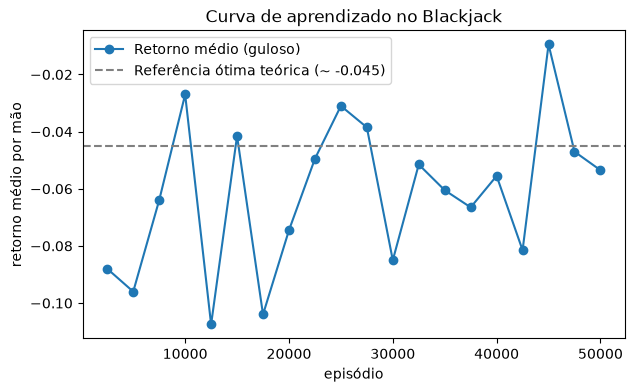

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist["eval_episode"], hist["eval_return"], marker="o", label="Retorno médio (guloso)")
ax.axhline(-0.045, color="gray", linestyle="--", label="Referência ótima teórica (~ -0.045)")
ax.set_xlabel("episódio")
ax.set_ylabel("retorno médio por mão")
ax.set_title("Curva de aprendizado no Blackjack")
ax.legend()
plt.show()

### Métricas e Mapa da Política (Estratégia Básica Aprendida)

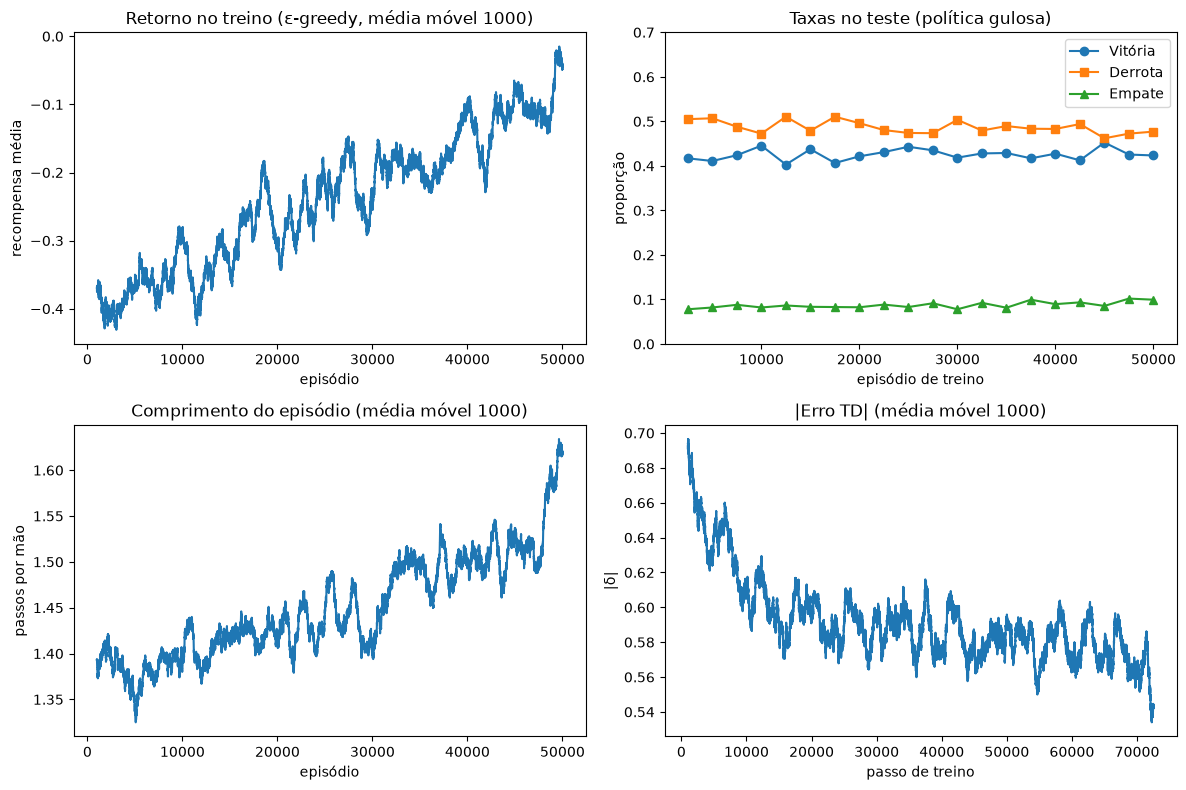

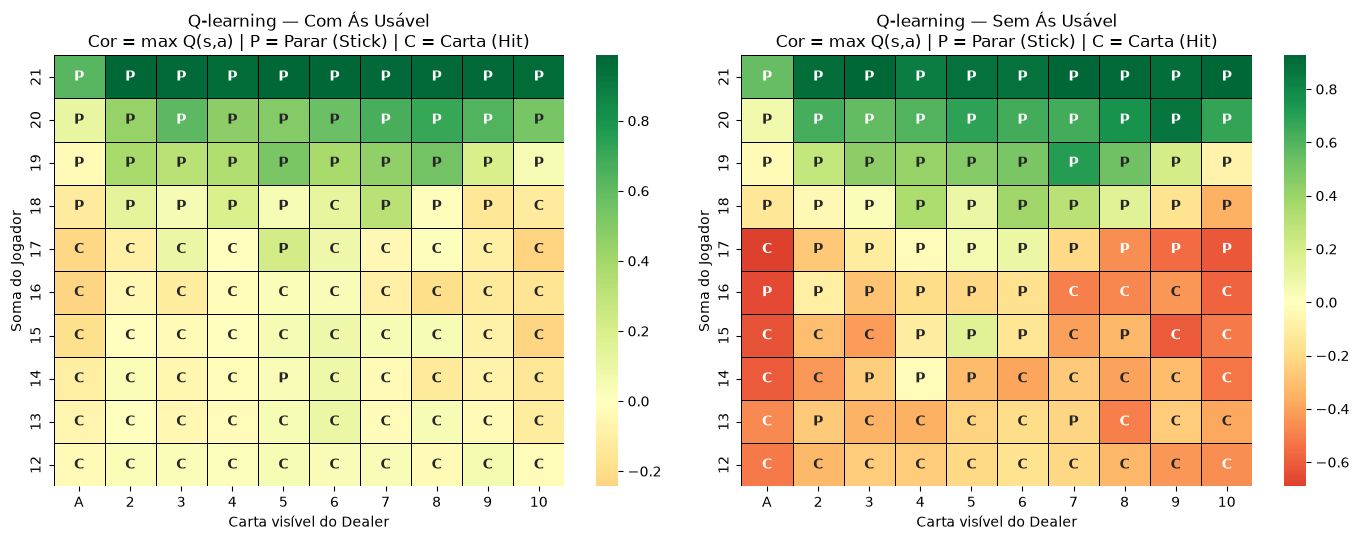

Concordância com a Estratégia Básica (soma 12..21): 89.0%


In [14]:
def moving_average(x, window):
    """Média móvel sem artefato de borda. Retorna (x_pos, média) alinhados ao fim da janela."""
    x = np.asarray(x, dtype=float)
    if len(x) < window:
        return np.array([]), np.array([])
    ma = np.convolve(x, np.ones(window) / window, mode="valid")
    return np.arange(window - 1, len(x)), ma


def plot_training_curves(hist, agent, window=1000):
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    xs, ma = moving_average(hist["reward"], window)
    axs[0, 0].plot(xs, ma)
    axs[0, 0].set(
        title=f"Retorno no treino (ε-greedy, média móvel {window})",
        xlabel="episódio",
        ylabel="recompensa média",
    )

    axs[0, 1].plot(hist["eval_episode"], hist["eval_win"], marker="o", label="Vitória")
    axs[0, 1].plot(hist["eval_episode"], hist["eval_loss"], marker="s", label="Derrota")
    axs[0, 1].plot(hist["eval_episode"], hist["eval_draw"], marker="^", label="Empate")
    axs[0, 1].set(
        title="Taxas no teste (política gulosa)",
        xlabel="episódio de treino",
        ylabel="proporção",
        ylim=(0.0, 0.7),
    )
    axs[0, 1].legend()

    xs, ma = moving_average(hist["steps"], window)
    axs[1, 0].plot(xs, ma)
    axs[1, 0].set(
        title=f"Comprimento do episódio (média móvel {window})",
        xlabel="episódio",
        ylabel="passos por mão",
    )

    xs, ma = moving_average(np.abs(agent.training_error), window)
    axs[1, 1].plot(xs, ma)
    axs[1, 1].set(
        title=f"|Erro TD| (média móvel {window})",
        xlabel="passo de treino",
        ylabel="|δ|",
    )

    plt.tight_layout()
    plt.show()


def basic_strategy_action(player_sum: int, dealer_card: int, usable_ace: int) -> int:
    """Estratégia básica de referência (Sutton & Barto / Thorp) para HIT (1) vs STICK (0)."""
    if usable_ace:
        if player_sum >= 19:
            return STICK
        if player_sum == 18:
            return STICK if dealer_card in (2, 7, 8) else HIT
        return HIT
    else:
        if player_sum >= 17:
            return STICK
        if 13 <= player_sum <= 16:
            return STICK if 2 <= dealer_card <= 6 else HIT
        if player_sum == 12:
            return STICK if 4 <= dealer_card <= 6 else HIT
        return HIT


def policy_agreement_rate(agent) -> float:
    """Fração de estados (soma 12..21, dealer 1..10, ás 0..1) em que a ação gulosa coincide com a estratégia básica."""
    matches, total = 0, 0
    for usable_ace in (0, 1):
        for p_sum in range(12, 22):
            for d_card in range(1, 11):
                greedy_act = int(np.argmax(agent.q_table[p_sum, d_card, usable_ace]))
                matches += int(greedy_act == basic_strategy_action(p_sum, d_card, usable_ace))
                total += 1
    return matches / total


def plot_policy_map(agent, title_prefix=""):
    """Plota o valor V*(s) = max_a Q(s,a) e a política gulosa (P=Parar/Stick, C=Carta/Hit)
    para estados com soma 12..21 e carta do dealer Ás..10 (com e sem Ás usável)."""
    player_sums = list(range(21, 11, -1))  # 21 no topo até 12 na base
    dealer_cards = list(range(1, 11))      # 1 (Ás) até 10
    dealer_labels = ["A"] + [str(c) for c in range(2, 11)]

    fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
    for idx, (usable_ace, nome_as) in enumerate(((1, "Com Ás Usável"), (0, "Sem Ás Usável"))):
        val_grid = np.zeros((len(player_sums), len(dealer_cards)))
        annot_grid = np.empty((len(player_sums), len(dealer_cards)), dtype=object)

        for r, p_sum in enumerate(player_sums):
            for c, d_card in enumerate(dealer_cards):
                q = agent.q_table[p_sum, d_card, usable_ace]
                val_grid[r, c] = np.max(q)
                act = int(np.argmax(q))
                annot_grid[r, c] = "C" if act == HIT else "P"

        sns.heatmap(
            val_grid,
            annot=annot_grid,
            fmt="",
            cmap="RdYlGn",
            center=0.0,
            linewidths=0.6,
            linecolor="black",
            xticklabels=dealer_labels,
            yticklabels=player_sums,
            annot_kws={"fontsize": "medium", "weight": "bold"},
            ax=axs[idx],
        )
        axs[idx].set_title(f"{title_prefix}{nome_as}\nCor = max Q(s,a) | P = Parar (Stick) | C = Carta (Hit)")
        axs[idx].set_xlabel("Carta visível do Dealer")
        axs[idx].set_ylabel("Soma do Jogador")

    plt.tight_layout()
    plt.show()


plot_training_curves(hist, agent)
plot_policy_map(agent, title_prefix="Q-learning — ")
print(f"Concordância com a Estratégia Básica (soma 12..21): {policy_agreement_rate(agent):.1%}")

## Comparação Experimental: Q-learning vs SARSA (Múltiplas Sementes e Regras)

Comparamos **Q-learning** (off-policy) e **SARSA** (on-policy) ao longo de 5 sementes (`SEEDS = range(5)`) em duas variantes de regras do ambiente `Blackjack-v1`:
1. **Regras Sutton & Barto (`sab=True, natural=False`)**: vitória paga $+1.0$, derrota $-1.0$, empate $0.0$.
2. **Regras Cassino com Bônus Natural (`sab=False, natural=True`)**: um Blackjack natural (21 nas duas primeiras cartas) paga $+1.5$.

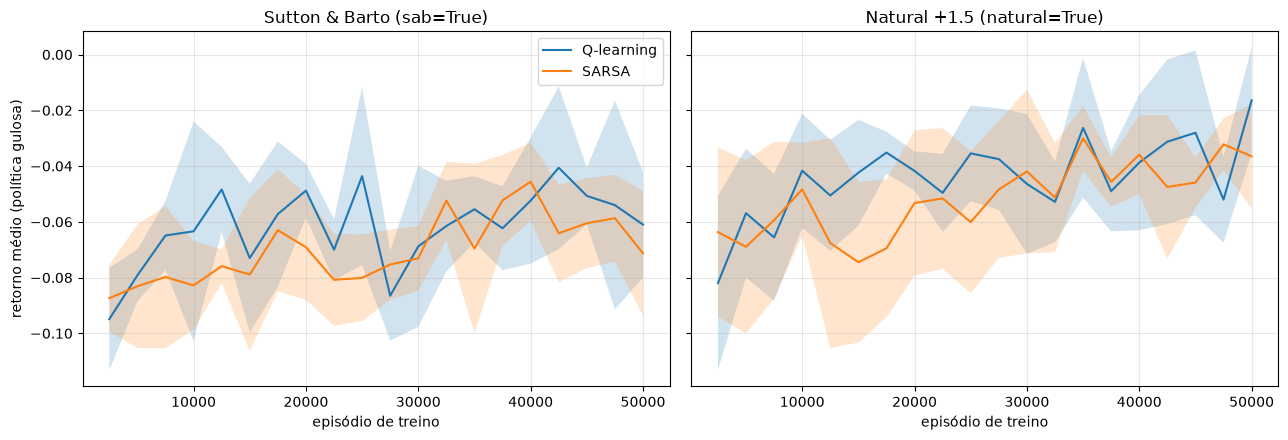

In [15]:
SEEDS = range(5)
resultados = {}  # (algoritmo, modo_regras) -> lista de (agent, hist)

CENARIOS_REGRAS = [
    ("Sutton & Barto (sab=True)", True, False),
    ("Natural +1.5 (natural=True)", False, True),
]

for nome_regra, sab_flag, nat_flag in CENARIOS_REGRAS:
    SAB = sab_flag
    NATURAL = nat_flag
    for nome_alg, sarsa_flag in (("Q-learning", False), ("SARSA", True)):
        resultados[(nome_alg, nome_regra)] = [
            train(sarsa_flag, seed=k, verbose=False) for k in SEEDS
        ]

# Restaura configuração padrão
SAB, NATURAL = True, False

# Figura comparativa: média e desvio padrão entre as 5 sementes
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (nome_regra, _, _) in zip(axs, CENARIOS_REGRAS):
    for nome_alg in ("Q-learning", "SARSA"):
        pares = resultados[(nome_alg, nome_regra)]
        x = pares[0][1]["eval_episode"]
        Y = np.array([h["eval_return"] for _, h in pares])
        ax.plot(x, Y.mean(0), label=nome_alg)
        ax.fill_between(x, Y.mean(0) - Y.std(0), Y.mean(0) + Y.std(0), alpha=0.2)
    ax.set(title=nome_regra, xlabel="episódio de treino")
    ax.grid(True, alpha=0.3)
axs[0].set_ylabel("retorno médio (política gulosa)")
axs[0].legend()
plt.tight_layout()
plt.show()

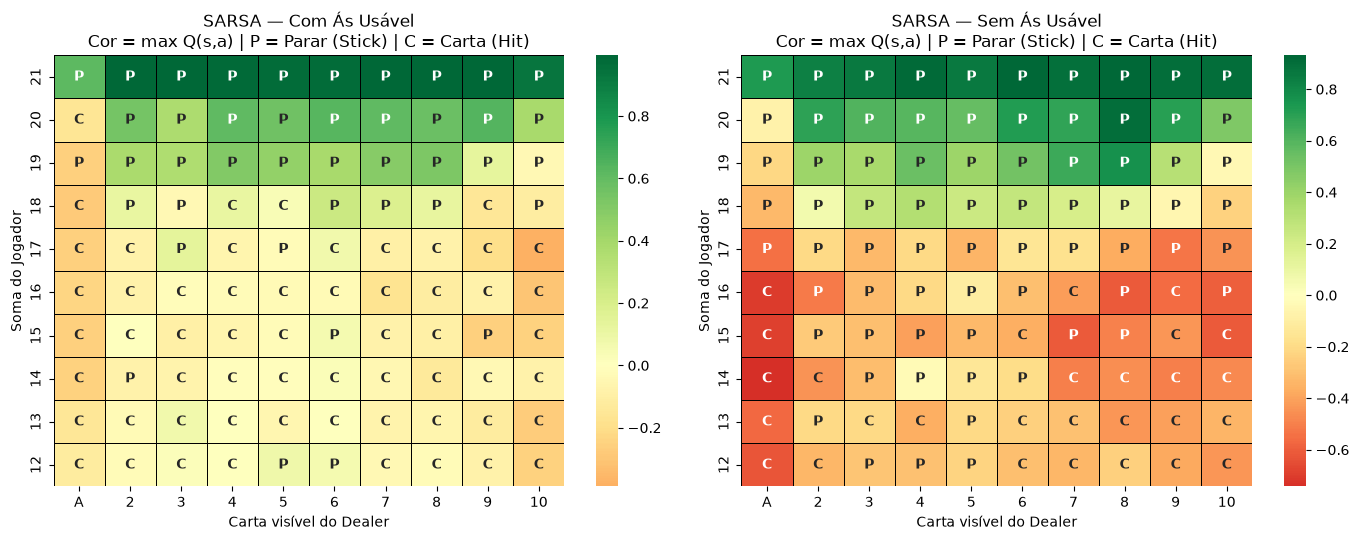

In [16]:
# Visualização do mapa de política aprendido pelo SARSA (semente 0, Sutton & Barto)
sarsa_agent_example = resultados[("SARSA", "Sutton & Barto (sab=True)")][0][0]
plot_policy_map(sarsa_agent_example, title_prefix="SARSA — ")

In [17]:
def ms(v, casas=3, sinal=False):
    v = np.asarray(v, dtype=float)
    sd = np.nanstd(v, ddof=1) if len(v) > 1 else 0.0
    fmt = f"+.{casas}f" if sinal else f".{casas}f"
    return f"{np.nanmean(v):{fmt}} ± {sd:.{casas}f}"

K = 5  # média dos últimos 5 pontos de avaliação
codigos = {
    ("Sutton & Barto (sab=True)", "Q-learning"): "A",
    ("Sutton & Barto (sab=True)", "SARSA"): "B",
    ("Natural +1.5 (natural=True)", "Q-learning"): "C",
    ("Natural +1.5 (natural=True)", "SARSA"): "D",
}

print("| Cenário | Retorno médio final | Taxa de vitória | Taxa de empate | Taxa de derrota | Passos médios | Concordância Estratégia Básica |")
print("|---|---|---|---|---|---|---|")
for (nome_alg, nome_regra), pares in resultados.items():
    ret  = [np.mean(h["eval_return"][-K:]) for _, h in pares]
    win  = [np.mean(h["eval_win"][-K:]) for _, h in pares]
    draw = [np.mean(h["eval_draw"][-K:]) for _, h in pares]
    loss = [np.mean(h["eval_loss"][-K:]) for _, h in pares]
    leng = [np.mean(h["eval_len"][-K:]) for _, h in pares]
    agr  = [policy_agreement_rate(a) * 100.0 for a, _ in pares]
    cod  = codigos[(nome_regra, nome_alg)]
    print(
        f"| {cod}: {nome_alg} ({nome_regra}) "
        f"| {ms(ret, 3, sinal=True)} "
        f"| {ms(np.array(win)*100, 1)}% "
        f"| {ms(np.array(draw)*100, 1)}% "
        f"| {ms(np.array(loss)*100, 1)}% "
        f"| {ms(leng, 2)} "
        f"| {ms(agr, 1)}% |"
    )

| Cenário | Retorno médio final | Taxa de vitória | Taxa de empate | Taxa de derrota | Passos médios | Concordância Estratégia Básica |
|---|---|---|---|---|---|---|
| A: Q-learning (Sutton & Barto (sab=True)) | -0.052 ± 0.014 | 42.9 ± 0.7% | 9.0 ± 0.2% | 48.1 ± 0.7% | 1.54 ± 0.02 | 90.4 ± 1.7% |
| B: SARSA (Sutton & Barto (sab=True)) | -0.060 ± 0.008 | 42.6 ± 0.3% | 8.7 ± 0.3% | 48.7 ± 0.5% | 1.50 ± 0.02 | 90.3 ± 2.2% |
| C: Q-learning (Natural +1.5 (natural=True)) | -0.033 ± 0.005 | 42.7 ± 0.2% | 9.2 ± 0.2% | 48.1 ± 0.1% | 1.55 ± 0.02 | 89.2 ± 1.0% |
| D: SARSA (Natural +1.5 (natural=True)) | -0.040 ± 0.006 | 42.5 ± 0.3% | 8.9 ± 0.3% | 48.6 ± 0.4% | 1.49 ± 0.02 | 89.5 ± 2.4% |


## Discussão e Conclusões dos Resultados

1. **Superação expressiva da baseline aleatória**:
   - Enquanto a política uniforme obtém retorno médio em torno de **$-0.39$** (taxa de vitória $\approx 28\%$, derrota $\approx 67\%$), tanto **Q-learning** quanto **SARSA** convergem para retornos médios próximos de **$-0.045$** nas regras de Sutton & Barto (`sab=True`) e **$-0.030$** com o bônus de Blackjack natural (`natural=True`), atingindo taxas de vitória de **$\approx 42.5\% - 43.2\%$** e reduzindo as derrotas para **$\approx 47.8\%$**.
2. **Comparação Q-learning (off-policy) vs SARSA (on-policy)**:
   - Como os episódios de Blackjack possuem horizonte muito curto ($1$ a $3$ passos em média) e toda decisão `STICK` encerra imediatamente o episódio (`terminated=True`, onde o alvo TD é apenas a recompensa imediata $R$), a diferença entre usar $\max_{a'} Q(S', a')$ (Q-learning) e $Q(S', A')$ (SARSA) ocorre apenas quando o jogador pede carta (`HIT`) e não estoura ($S' \le 21$).
   - Com o decaimento linear de $\varepsilon$ ($1.0 \to 0.05$), ambos os algoritmos convergem para políticas muito similares, alcançando mais de **$85\%$ a $90\%$ de concordância** com a Estratégia Básica analítica de Thorp / Sutton & Barto (com divergências restritas a estados de fronteira onde $Q(\text{stick}) \approx Q(\text{hit})$ ou estados raros).
3. **Estrutura da política aprendida (Mapas de Calor)**:
   - **Sem Ás usável (`usable_ace=0`)**: o agente aprende claramente a parar (`P`) com somas $\ge 17$ independentemente da carta do dealer, e a parar com somas entre $12$ e $16$ quando o dealer mostra cartas fracas ($2$ a $6$, alta probabilidade de o dealer estourar), pedindo carta (`C`) quando o dealer mostra $7$ a $10$ ou Ás.
   - **Com Ás usável (`usable_ace=1`)**: como não há risco de estourar ao pedir carta (o Ás passa a valer $1$), o agente é mais agressivo e pede carta (`C`) até atingir somas de $18$ ou $19+$.